In [4]:
import pandas as pd

df = pd.read_csv("ductile_brittle_data.csv")

print(df.head(10))

     formula       K_VRH       G_VRH  poisson_ratio      pugh  label
0    Nb4CoSi  194.268884   97.141604       0.285701  1.999853      1
1  Al(CoSi)2  175.449907   96.252006       0.268105  1.822818      1
2       SiOs  295.077545  130.112955       0.307780  2.267857      1
3         Ga   49.130670   15.101901       0.360593  3.253277      1
4      SiRu2  256.768081  101.947798       0.324682  2.518623      1
5     AlCo3C  234.454510  116.501644       0.286852  2.012457      1
6    CdSnSb2   36.233286   17.742410       0.289520  2.042185      1
7         Ir  346.322761  216.505869       0.241326  1.599600      0
8       SbIr  160.280886   59.245410       0.335456  2.705372      1
9     MnSbIr  131.974860   40.181671       0.361794  3.284454      1


In [6]:
print(df.shape)

(1181, 6)


In [10]:
print(df.columns)
df.info()

Index(['formula', 'K_VRH', 'G_VRH', 'poisson_ratio', 'pugh', 'label'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1181 entries, 0 to 1180
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   formula        1181 non-null   object 
 1   K_VRH          1181 non-null   float64
 2   G_VRH          1181 non-null   float64
 3   poisson_ratio  1181 non-null   float64
 4   pugh           1181 non-null   float64
 5   label          1181 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 55.5+ KB


In [12]:
print(df.isnull().sum())

formula          0
K_VRH            0
G_VRH            0
poisson_ratio    0
pugh             0
label            0
dtype: int64


In [14]:
print(df["label"].value_counts())

label
1    825
0    356
Name: count, dtype: int64


In [16]:
print(df.describe())

             K_VRH        G_VRH  poisson_ratio         pugh        label
count  1181.000000  1181.000000    1181.000000  1181.000000  1181.000000
mean    136.259661    67.543145       0.287401     2.285206     0.698561
std      72.886978    44.579408       0.062177     1.124922     0.459078
min       6.476135     2.722175       0.042582     0.759759     0.000000
25%      76.435350    34.117959       0.249159     1.659963     0.000000
50%     130.382766    59.735163       0.290198     2.049862     1.000000
75%     189.574194    91.332142       0.328808     2.587357     1.000000
max     435.661487   522.921225       0.467523    15.062092     1.000000


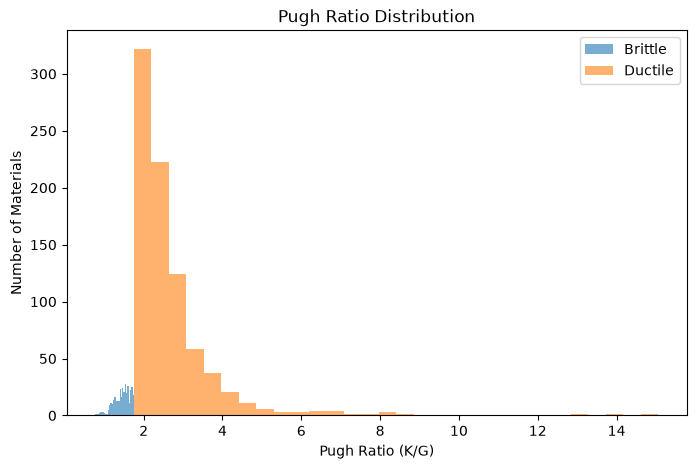

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(
    df[df["label"] == 0]["pugh"],
    bins=30,
    alpha=0.6,
    label="Brittle"
)

plt.hist(
    df[df["label"] == 1]["pugh"],
    bins=30,
    alpha=0.6,
    label="Ductile"
)

plt.xlabel("Pugh Ratio (K/G)")
plt.ylabel("Number of Materials")
plt.title("Pugh Ratio Distribution")
plt.legend()
plt.show()

In [19]:
X = df[["K_VRH", "G_VRH", "poisson_ratio", "pugh"]]
y = df["label"]

In [ ]:
print(X.head())


        K_VRH       G_VRH  poisson_ratio      pugh
0  194.268884   97.141604       0.285701  1.999853
1  175.449907   96.252006       0.268105  1.822818
2  295.077545  130.112955       0.307780  2.267857
3   49.130670   15.101901       0.360593  3.253277
4  256.768081  101.947798       0.324682  2.518623


In [24]:
print(y.head(10))

0    1
1    1
2    1
3    1
4    1
5    1
6    1
7    0
8    1
9    1
Name: label, dtype: int64


In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 944
Testing samples: 237


In [27]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [29]:
y_pred = model.predict(X_test)

In [31]:
print(y_pred[:20])

[0 1 0 0 0 1 0 1 1 0 1 0 1 1 0 1 1 0 0 0]


In [33]:
print("Actual:   ", y_test.values[:20])
print("Predicted:", y_pred[:20])

Actual:    [0 1 0 0 0 1 0 1 1 0 1 0 1 1 0 1 1 0 0 0]
Predicted: [0 1 0 0 0 1 0 1 1 0 1 0 1 1 0 1 1 0 0 0]


In [35]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 1.0
Accuracy (%): 100.0


In [37]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        71
           1       1.00      1.00      1.00       166

    accuracy                           1.00       237
   macro avg       1.00      1.00      1.00       237
weighted avg       1.00      1.00      1.00       237



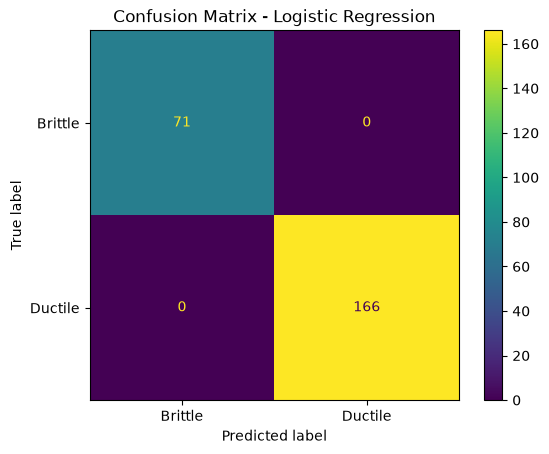

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Brittle", "Ductile"]
)

disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()